# 01. Analyse Exploratoire des Biscuits (EDA). Objectifs : Valider l'intégrité des données après ingestion DuckDB et analyser les corrélations entre nutriments et Nutriscore.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

# Chargement du dataset et aplatissement de la structure 'products'
with open('../data/raw/off_biscuits_fr.json', 'r') as f:
    data = json.load(f)
df = pd.DataFrame(data['products'])

df.head()

,product_name,nutriscore_grade,energy_100g,sugars_100g,fat_100g
0,Madeleine Framboise,unknown,NaN,NaN,NaN
1,The simpsons donuts,e,470.0,18.200001,28.900000
2,Eclairs,d,237.0,21.700001,9.500000
3,Beignets gourmands parfum choco-noisettes,c,406.0,5.400000,20.000000
4,Muffin double chocolat,d,390.0,26.799999,24.299999


In [2]:
# Analyse de la structure et des valeurs manquantes
print(df.info())
print("\nStatistiques descriptives :")
print(df.describe())
print("\nValeurs manquantes par colonne :")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   product_name      1000 non-null   str    
 1   nutriscore_grade  1000 non-null   str    
 2   energy_100g       959 non-null    float64
 3   sugars_100g       957 non-null    float64
 4   fat_100g          954 non-null    float64
dtypes: float64(3), str(2)
memory usage: 39.2 KB
None

Statistiques descriptives :
        energy_100g  sugars_100g    fat_100g
count    959.000000   957.000000  954.000000
mean     455.889835    23.778799   19.240849
std     1186.309468    14.369538    8.027132
min        0.000000     0.000000    0.000000
25%      368.000000    14.000000   13.400000
50%      436.000000    22.000000   20.000000
75%      483.000000    34.000000   25.000000
max    37000.000000   150.887573   75.000000

Valeurs manquantes par colonne :
product_name         0
nutriscore_grade     0
energy_10

## Analyse de la distribution du Nutriscore.

/tmp/ipykernel_105508/520938044.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='nutriscore_grade', order=['a', 'b', 'c', 'd', 'e'], palette='viridis')


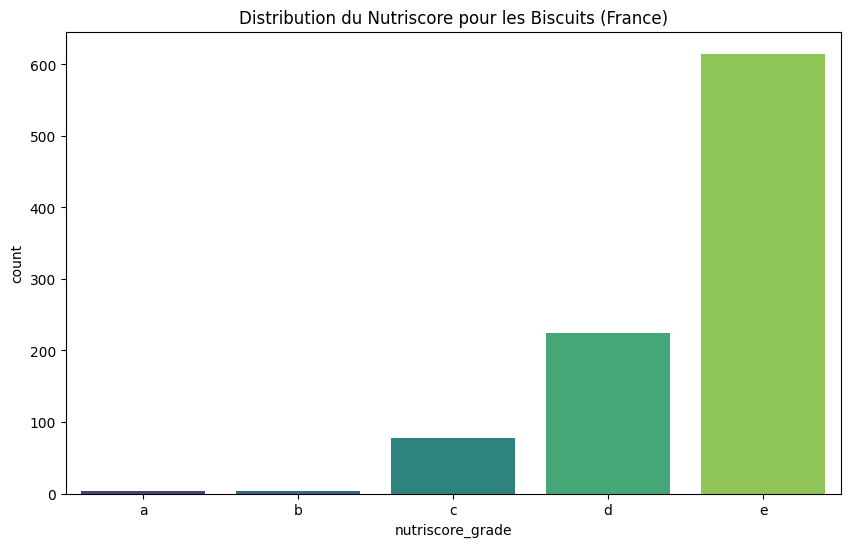

In [3]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='nutriscore_grade', order=['a', 'b', 'c', 'd', 'e'], palette='viridis')
plt.title('Distribution du Nutriscore pour les Biscuits (France)')
plt.show()

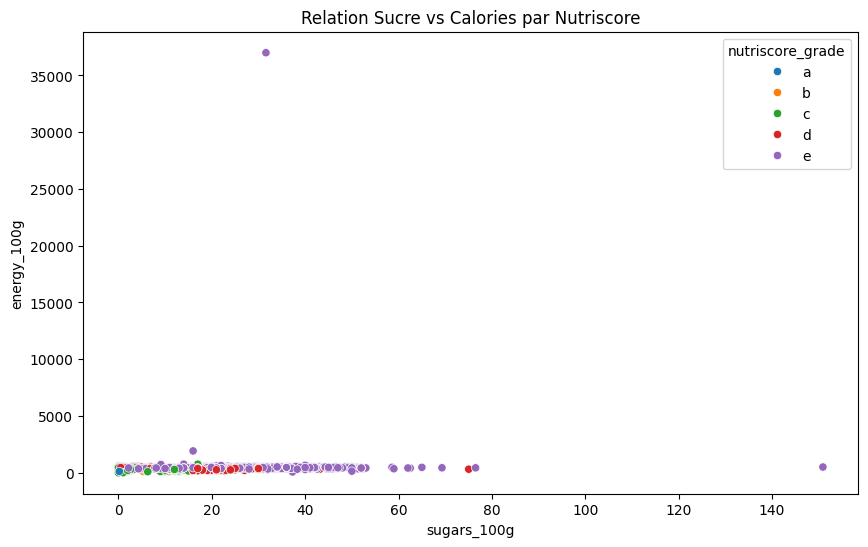

In [4]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='sugars_100g', y='energy_100g', hue='nutriscore_grade', hue_order=['a', 'b', 'c', 'd', 'e'])
plt.title('Relation Sucre vs Calories par Nutriscore')
plt.show()